In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [38]:
df = pd.read_csv('ushape.csv')

In [39]:
df.head()

,x,y,class
0,2.115098,-0.046244,1.0
1,0.882490,-0.075756,0.0
2,-0.055144,-0.037332,1.0
3,0.829545,-0.539321,1.0
4,2.112857,0.662084,1.0


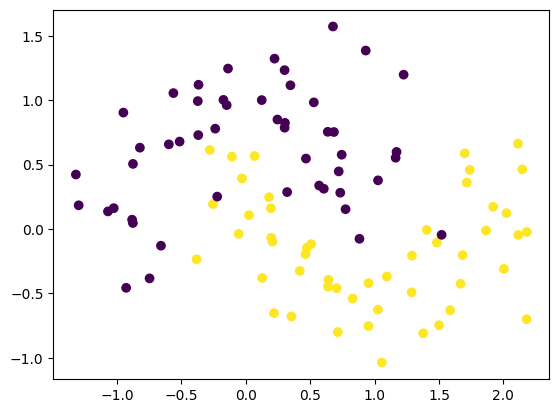

In [40]:
plt.scatter(df['x'],df['y'],c=df['class'])

In [41]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [42]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [43]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2,kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
model.get_weights()

[array([[-0.2484028 ,  1.8708179 , -0.16396277, -0.6053171 ,  0.4404291 ,
          0.39062753, -0.09526965, -0.9223958 , -1.195296  ,  0.35156924],
        [ 0.9998269 ,  0.14502615,  1.7274458 , -0.46200615,  0.12010369,
          1.1208296 , -0.26281738,  0.3049488 , -0.68916875, -0.2539866 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.7991977 ,  0.6405945 ,  0.24345459,  0.3883177 , -0.03703161,
          0.2547333 , -0.94262546,  0.9094952 ,  0.5294302 ,  0.25152564],
        [-0.31626064,  0.26508027, -0.943432  ,  0.17509715, -0.14834607,
          0.12076677, -0.6370349 , -0.81464684,  0.01112662, -0.17845424],
        [ 0.18179825, -0.36629462, -0.34429002,  0.18806903,  0.03644242,
          0.39591935,  0.18207064,  0.21516103,  0.12970619, -0.7410454 ],
        [-0.23556694,  0.5140744 , -0.17440477,  0.08539429,  0.11200471,
          0.4264717 ,  0.57410604, -0.6369979 ,  0.26455083,  0.20870623],
        [ 0.87251

In [45]:
initial_weights = model.get_weights()

In [46]:
initial_weights[0] = np.random.randn(2,10)*np.sqrt(2/2)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(2/10)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(2/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(2/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(2/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [47]:
model.set_weights(initial_weights)

In [48]:
model.get_weights()

[array([[-0.66223943,  1.2653424 , -1.1867062 , -1.0236093 , -0.43327108,
         -0.94961435,  0.2576857 ,  0.5629856 , -0.47264084, -0.20787703],
        [ 0.93676054,  0.4576351 , -1.0139962 , -0.44515976, -0.35109752,
          0.4030994 ,  0.12200917,  0.45108467, -1.2347351 , -0.51470447]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.31851333,  1.097872  ,  0.1047449 , -1.0596637 , -0.6735885 ,
          0.37711078, -0.16031821,  0.18359992,  0.0328064 , -0.02132996],
        [-0.00267028,  0.98831236, -0.4004549 , -0.20683187,  0.01519774,
         -0.01417561, -0.334727  ,  0.13813563, -0.04796965,  0.09938467],
        [ 0.16134422, -0.1843717 ,  0.23748402, -0.3663684 ,  0.19925119,
         -0.20945413, -0.3924723 ,  0.3981565 ,  0.00907844,  0.78775376],
        [-0.31165105, -0.16057341,  0.04762491,  0.10444912, -0.17309563,
          0.15783785,  0.33757064, -0.11733787, -0.03386966,  0.2631568 ],
        [ 0.45338

In [49]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [50]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 162ms/step - accuracy: 0.4684 - loss: 0.8444 - val_accuracy: 0.4000 - val_loss: 0.8577
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.4684 - loss: 0.8273 - val_accuracy: 0.4000 - val_loss: 0.8411
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.4684 - loss: 0.8102 - val_accuracy: 0.4000 - val_loss: 0.8256
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.4684 - loss: 0.7967 - val_accuracy: 0.4000 - val_loss: 0.8109
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.4684 - loss: 0.7840 - val_accuracy: 0.4500 - val_loss: 0.7976
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.4684 - loss: 0.7706 - val_accuracy: 0.4500 - val_loss: 0.7856
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.4937 - loss: 0.7592 - val_accuracy: 0.4500 - val_loss: 0.7741
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5190 - loss: 0.7481 - val_accuracy: 0.5000 - val_loss: 0.7628
Epo

In [51]:
model.get_weights()

[array([[-0.3845576 ,  1.1871367 , -1.2766621 , -1.0597975 , -0.18877806,
         -0.8093248 ,  0.17874585,  0.7015193 , -0.29064986, -0.19972658],
        [ 1.1915874 ,  0.5884507 , -1.0310044 , -0.52641755, -0.5605731 ,
          0.30893713,  0.2554688 ,  0.2738738 , -1.4295169 , -0.55654025]],
       dtype=float32),
 array([ 0.2507963 , -0.06722573, -0.02809018, -0.06905495,  0.20534348,
        -0.01558186,  0.11816905, -0.10272761,  0.21992779,  0.08417188],
       dtype=float32),
 array([[-6.42996252e-01,  1.30055988e+00,  5.04752547e-02,
         -1.05966365e+00, -6.73588514e-01,  6.01969838e-01,
         -1.96593642e-01, -7.37354383e-02,  1.29368201e-01,
         -5.35181761e-02],
        [ 2.09063053e-01,  9.10158455e-01, -4.46738601e-01,
         -2.06831872e-01,  1.51977390e-02,  8.42032656e-02,
         -2.76816577e-01,  2.15508893e-01, -9.51339453e-02,
          2.53444929e-02],
        [ 7.77440146e-02, -2.01064395e-05,  4.15740162e-01,
         -3.66368413e-01,  1.99251

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step


<Axes: >

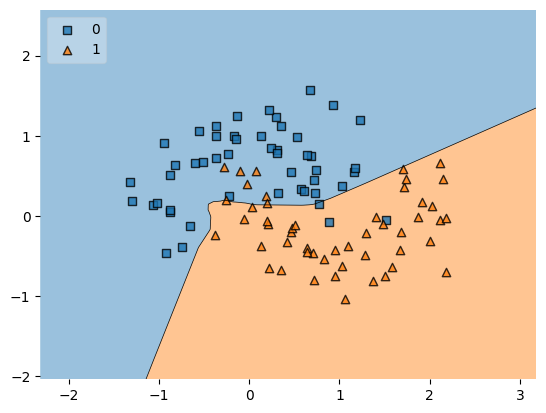

In [52]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X,y.astype('int'), clf=model, legend=2)

In [53]:
(np.random.randn(10,10)*0.01).min()

np.float64(-0.02364722985077607)

In [54]:
(np.random.randn(10,10)*0.01).max()

np.float64(0.02216953764485923)